In [7]:
import os
import dnbr_mensual as dn

In [8]:
import ee
ee.Authenticate(auth_mode='notebook')   # una vez por sesión

True

In [5]:
ruta = dn.procesar(2020, 'ucayali', (-74.5, -9.5, -73.5, -8.5),
                   project='vmt-waaa') # Cambiar el projecto por el que se usa (ej. vmt-waaa)

ucayali 2020: 16 teselas de 0.25 grados, ~111 m por píxel
  [1/16] f0 c0: 1.0 MB
  [2/16] f0 c1: 1.0 MB
  [3/16] f0 c2: 1.0 MB
  [4/16] f0 c3: 0.9 MB
  [5/16] f1 c0: 1.0 MB
  [6/16] f1 c1: 1.0 MB
  [7/16] f1 c2: 1.0 MB
  [8/16] f1 c3: 1.0 MB
  [9/16] f2 c0: 1.0 MB
  [10/16] f2 c1: 1.0 MB
  [11/16] f2 c2: 1.0 MB
  [12/16] f2 c3: 1.0 MB
  [13/16] f3 c0: 1.0 MB
  [14/16] f3 c1: 1.0 MB
  [15/16] f3 c2: 1.0 MB
  [16/16] f3 c3: 1.0 MB
Guardado salidas_dnbr/dnbr_ucayali_2020.tif
Extensión verificada: (-74.5, -9.5, -73.5, -8.5), 12 bandas


In [9]:
cajas = {

    "bolivia_beni": (-67.0, -14.0, -66.0, -13.0),
    "chile_nuble":  (-72.0, -37.5, -71.0, -36.5),
    "ucayali":      (-74.5, -9.5, -73.5, -8.5),
}
for nombre, bbox in cajas.items():
    for year in (2019, 2020, 2021):
        if os.path.exists(f"salidas_dnbr/dnbr_{nombre}_{year}.tif"):
            continue
        try:
            dn.procesar(year, nombre, bbox, project="vmt-waaa")
        except Exception as error:
            print("FALLO", nombre, year, error)

bolivia_beni 2019: 16 teselas de 0.25 grados, ~111 m por píxel
  [1/16] f0 c0: 1.1 MB
  [2/16] f0 c1: 1.1 MB
  [3/16] f0 c2: 1.1 MB
  [4/16] f0 c3: 1.1 MB
  [5/16] f1 c0: 1.1 MB
  [6/16] f1 c1: 1.1 MB
  [7/16] f1 c2: 1.1 MB
  [8/16] f1 c3: 1.1 MB
  [9/16] f2 c0: 1.0 MB
  [10/16] f2 c1: 1.1 MB
  [11/16] f2 c2: 1.1 MB
  [12/16] f2 c3: 1.1 MB
  [13/16] f3 c0: 0.8 MB
  [14/16] f3 c1: 1.1 MB
  [15/16] f3 c2: 1.1 MB
  [16/16] f3 c3: 1.1 MB
Guardado salidas_dnbr/dnbr_bolivia_beni_2019.tif
Extensión verificada: (-67.0, -14.0, -66.0, -13.0), 12 bandas
bolivia_beni 2020: 16 teselas de 0.25 grados, ~111 m por píxel
  [1/16] f0 c0: 1.1 MB
  [2/16] f0 c1: 1.1 MB
  [3/16] f0 c2: 1.1 MB
  [4/16] f0 c3: 1.1 MB
  [5/16] f1 c0: 1.1 MB
  [6/16] f1 c1: 1.1 MB
  [7/16] f1 c2: 1.1 MB
  [8/16] f1 c3: 1.1 MB
  [9/16] f2 c0: 1.0 MB
  [10/16] f2 c1: 1.1 MB
  [11/16] f2 c2: 1.1 MB
  [12/16] f2 c3: 1.1 MB
  [13/16] f3 c0: 0.8 MB
  [14/16] f3 c1: 1.1 MB
  [15/16] f3 c2: 1.1 MB
  [16/16] f3 c3: 1.1 MB
Guardado sali

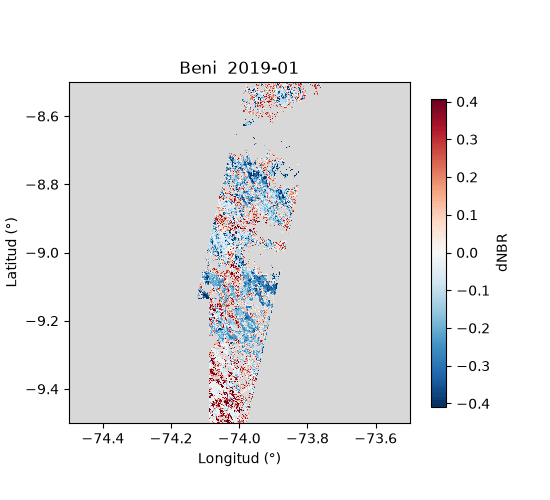

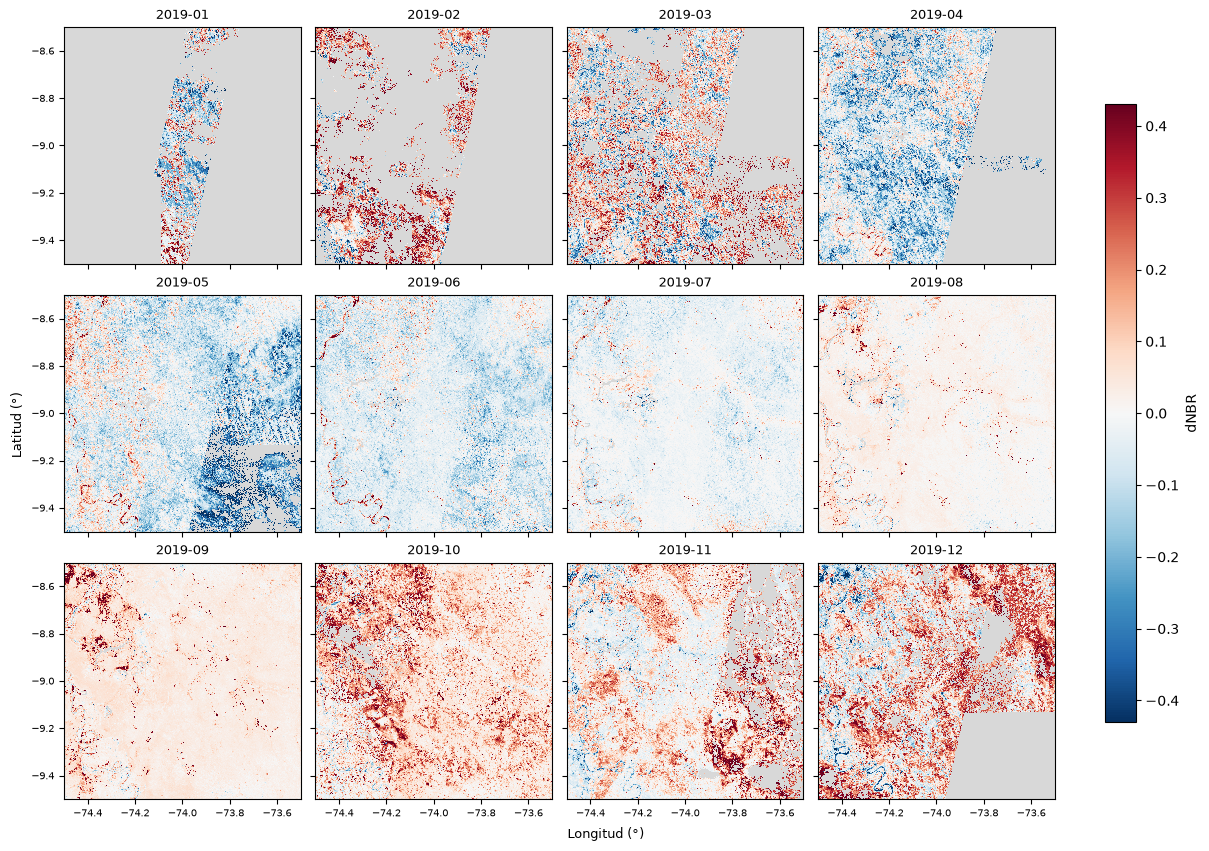

In [10]:
import dnbr_vis as dv

rutas = [f"salidas_dnbr/dnbr_ucayali_{y}.tif" for y in (2019, 2020, 2021)]
da = dv.leer_dnbr(rutas)            # 36 meses

fig = dv.panel_mensual(da.sel(tiempo="2019"))   # un año a la vez para el panel
ruta = dv.animar(da, "ucayali.gif", titulo="Beni")

from IPython.display import Image
Image(filename=ruta)